# gpOptimizer: Single-Task Acquisition Functions

In [1]:
#!pip install gpcam~=8.7.0
#!pip install matplotlib

## Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from gpcam import GPOptimizer
import time
from loguru import logger
from distributed import Client
client = Client()


%load_ext autoreload
%autoreload 2

In [3]:
from itertools import product
x_pred1D = np.linspace(0,1,1000).reshape(-1,1)

## Data Preparation

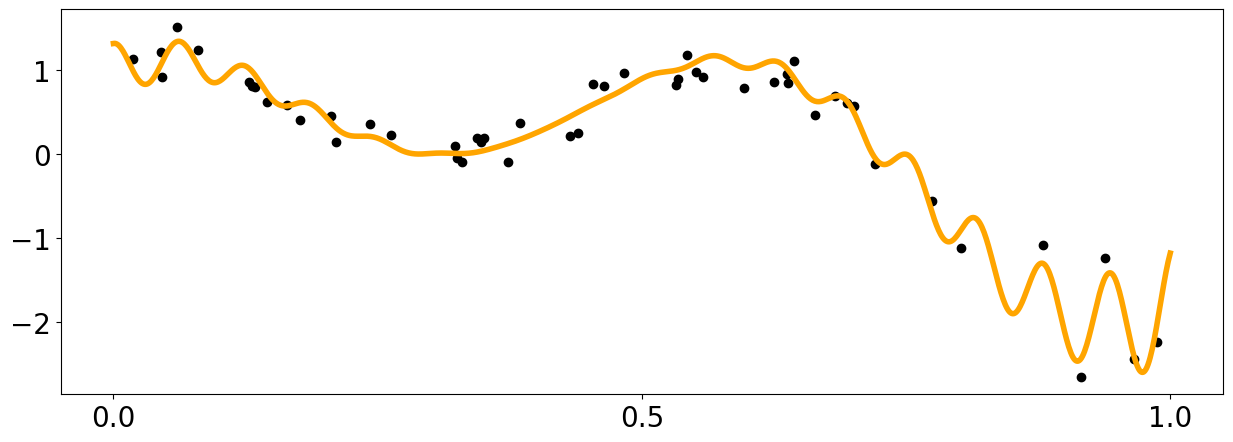

In [4]:
x = np.linspace(0,600,1000)
def f1(x):
    return np.sin(5. * x) + np.cos(10. * x) + (2.* (x-0.4)**2) * np.cos(100. * x)
 
x_data = np.random.rand(50).reshape(-1,1) 
y_data = f1(x_data[:,0]) + (np.random.rand(len(x_data))-0.5) * 0.5

plt.figure(figsize = (15,5))
plt.xticks([0.,0.5,1.0])
plt.yticks([-2,-1,0.,1])
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.plot(x_pred1D,f1(x_pred1D), color = 'orange', linewidth = 4)
plt.scatter(x_data[:,0],y_data, color = 'black')

## Customizing the Gaussian Process

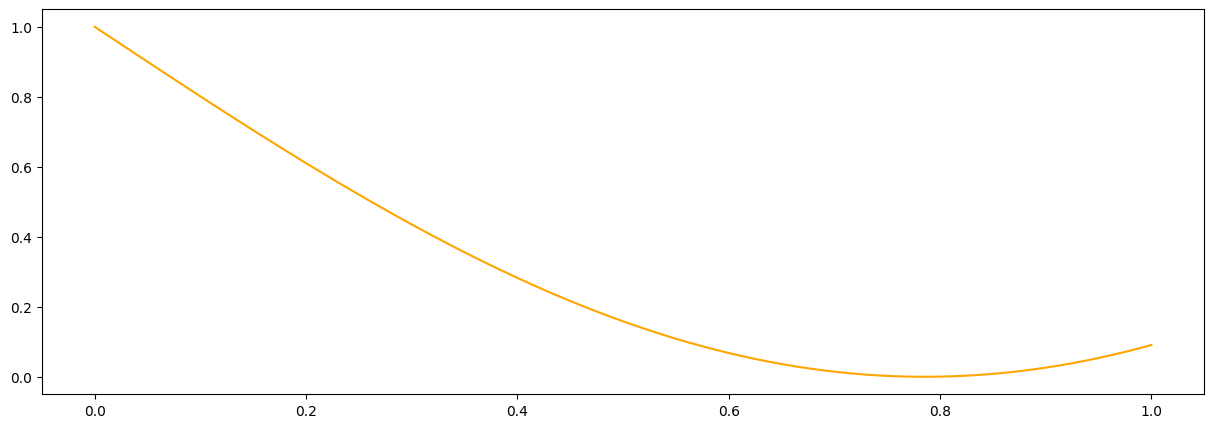

In [5]:
def my_noise(x,hps):
    #This is a simple noise function but can be made arbitrarily complex using many hyperparameters.
    #The noise function can return a matrix or a vector 
    return np.zeros((len(x))) + hps[2]

#stationary
from gpcam.kernels import *
def skernel(x1,x2,hps):
    #The kernel follows the mathematical definition of a kernel. This
    #means there is no limit to the variety of kernels you can define.
    d = get_distance_matrix(x1,x2)
    return hps[0] * matern_kernel_diff1(d,hps[1])


def meanf(x, hps):
    #This is a simple mean function but it can be arbitrarily complex using many hyperparameters.
    return 1.-np.sin(hps[3] * x[:,0])
#it is a good idea to plot the prior mean function to make sure we did not mess up
plt.figure(figsize = (15,5))
plt.plot(x_pred1D,meanf(x_pred1D, np.array([1.,1.,5.0,2.])), color = 'orange', label = 'task1')

## Initialization

In [6]:
my_gpo = GPOptimizer(x_data,y_data,
            init_hyperparameters = np.ones((4))/10.,  # We need enough of those for kernel, noise, and prior mean functions
            compute_device='cpu',
            kernel_function=skernel,
            kernel_function_grad=None,
            prior_mean_function=meanf,
            prior_mean_function_grad=None,
            noise_function=my_noise,
            #noise_variances=np.zeros(y_data.shape) + 0.1,
            gp2Scale = False,
            gradient_per_direction=False,
            args={'a': 1.5, 'b':2.},  # read by the 'target probability' acquisition function
            )

hps_bounds = np.array([[0.01,10.], #signal variance for the kernel
                       [0.01,10.], #length scale for the kernel
                       [0.00001,0.1],  #noise
                       [0.00001,1.]  #mean
                      ])

#the following is not needed; this is just to show how data is replaced or appended
x_update = np.array([0.1,0.2,0.5]).reshape(3,1)
y_update = f1(x_update[:,0]) + (np.random.rand(len(x_update))-0.5) * 0.5
my_gpo.tell(x_update, y_update, append=True) ##append to the data
my_gpo.tell(x_data, y_data, append=False) ## back to normal overwriting the updated data

## Training

`train()` finds the hyperparameters, sets them on the GP, and returns them. `method` chooses how:

| method | what it does | good for |
|---|---|---|
| `None` (default) | `local` from `n_restarts=5` starting points, best kept | most problems |
| `"local"` | gradient-based (L-BFGS-B) from `n_restarts` starts | fast, smooth likelihoods |
| `"global"` | differential evolution | rugged likelihoods, few hyperparameters |
| `"hgdl"` | hybrid global-local, local runs spread over a Dask cluster | HPC, many hyperparameters |
| `"mcmc"` | adaptive Metropolis; the trained values are the posterior median | hyperparameter uncertainty |
| `"adam"` | stochastic gradient descent | very large problems |
| `"bo"` | Bayesian optimization of the likelihood | expensive, noisy likelihoods (gp2Scale) |
| a callable | your own optimizer: takes the GP, returns hyperparameters | anything else |

A user `objective_function` (with its gradient) replaces the log marginal likelihood as the
criterion. With `accept_only_if_improved=True` (the default), a `local`, `hgdl`, `adam` or callable
run that ends worse than the hyperparameters it started from is rolled back, with a warning.

Every run below starts from the same hyperparameters, so their results can be compared.

In [7]:
def reset():
    my_gpo.set_hyperparameters(np.ones((4))/10.)

def report(name, t0):
    print(f"{name:28s} hps = {np.round(my_gpo.hyperparameters, 4)},  "
          f"log marginal likelihood = {my_gpo.log_likelihood():9.3f},  {time.time() - t0:5.1f} s")

### Local optimization (the default)

In [8]:
reset(); t0 = time.time()
my_gpo.train(hyperparameter_bounds=hps_bounds)  # method=None: local, 5 starting points
report("default (local, 5 starts)", t0)

reset(); t0 = time.time()
my_gpo.train(hyperparameter_bounds=hps_bounds, method="local", n_restarts=1)
report("local, a single start", t0)

default (local, 5 starts)    hps = [2.2389 0.4314 0.0667 1.    ],  log marginal likelihood =   -18.854,    0.2 s
local, a single start        hps = [2.2389 0.4314 0.0667 1.    ],  log marginal likelihood =   -18.854,    0.0 s


### Global optimization

In [9]:
reset(); t0 = time.time()
my_gpo.train(hyperparameter_bounds=hps_bounds, method="global", max_iter=20)
report("global", t0)

global                       hps = [2.2733 0.4351 0.0659 0.9979],  log marginal likelihood =   -18.856,    0.4 s


### HGDL
Hybrid global-local optimization; the local runs are distributed over the Dask client.

In [10]:
reset(); t0 = time.time()
my_gpo.train(hyperparameter_bounds=hps_bounds, method="hgdl", max_iter=2, dask_client=client)
report("hgdl", t0)

hgdl                         hps = [2.2391 0.4324 0.0666 1.    ],  log marginal likelihood =   -18.854,    1.7 s


### MCMC
Samples the hyperparameter posterior; the trained hyperparameters are the median of the chain after
burn-in. The chain and its summaries land in `mcmc_info`.

mcmc                         hps = [5.8762 0.603  0.0713 0.5568],  log marginal likelihood =   -19.380,    0.5 s
chain length: 2900  acceptance rate: 0.253
posterior std of the hyperparameters: [2.6794 0.1682 0.0127 0.3049]


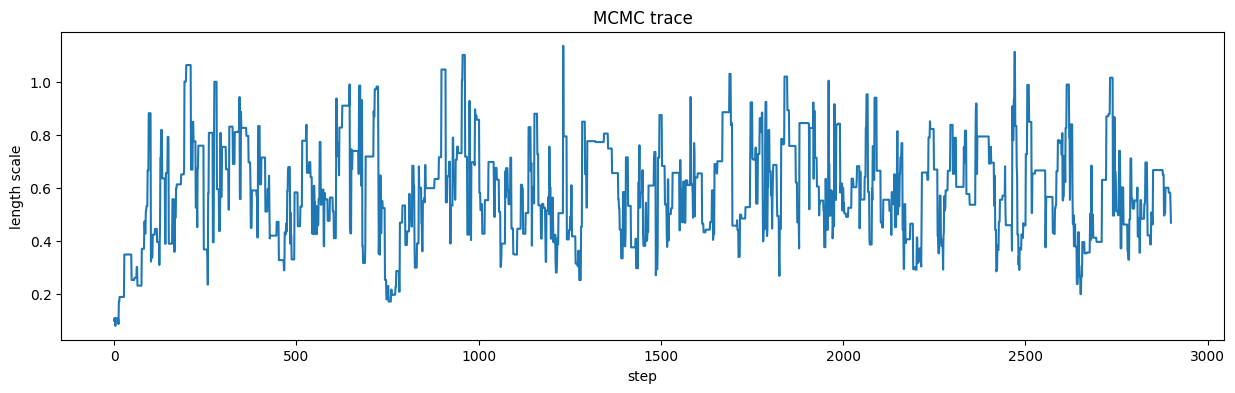

In [11]:
reset(); t0 = time.time()
my_gpo.train(hyperparameter_bounds=hps_bounds, method="mcmc", max_iter=5000)
report("mcmc", t0)
info = my_gpo.mcmc_info
print("chain length:", len(info["x"]), " acceptance rate:", np.round(info["acceptance rate"], 3))
print("posterior std of the hyperparameters:", np.round(np.sqrt(info["var(x)"]), 4))

plt.figure(figsize=(15, 4))
plt.plot(info["x"][:, 1])
plt.xlabel("step"); plt.ylabel("length scale"); plt.title("MCMC trace")
plt.show()

### ADAM

In [12]:
reset(); t0 = time.time()
my_gpo.train(hyperparameter_bounds=hps_bounds, method="adam", max_iter=100)
report("adam", t0)

adam                         hps = [0.482  0.2231 0.0673 0.7041],  log marginal likelihood =   -21.796,    0.1 s


### Bayesian optimization
`max_iter` is a budget of likelihood evaluations here, and the search usually stops earlier. `bo_info`
also ranks which hyperparameters matter. On a cheap, exact likelihood like this one, local optimization
is the better choice; BO is for likelihoods too expensive or noisy for it.

In [13]:
reset(); t0 = time.time()
my_gpo.train(hyperparameter_bounds=hps_bounds, method="bo", max_iter=40)
report("bo", t0)
info = my_gpo.bo_info
print("likelihood evaluations:", info["n_evaluations"], " stopping reason:", info["stopping reason"])
print("relative sensitivity of the likelihood to each hyperparameter:", np.round(info["sensitivity"] / np.sum(info["sensitivity"]), 3))

bo                           hps = [1.5502 0.4372 0.0777 1.    ],  log marginal likelihood =   -19.436,    0.5 s
likelihood evaluations: 22  stopping reason: converged
relative sensitivity of the likelihood to each hyperparameter: [0.698 0.156 0.113 0.033]


### Your own training method
Any callable that takes the GP and returns a hyperparameter vector, here scipy's Nelder-Mead.

In [14]:
from scipy.optimize import minimize

def nelder_mead(gp):
    res = minimize(lambda h: -gp.log_likelihood(hyperparameters=h), gp.hyperparameters,
                   method="Nelder-Mead", bounds=hps_bounds, options={"maxiter": 500})
    return res.x

reset(); t0 = time.time()
my_gpo.train(hyperparameter_bounds=hps_bounds, method=nelder_mead)
report("callable (Nelder-Mead)", t0)

callable (Nelder-Mead)       hps = [2.2088 0.4302 0.1    1.    ],  log marginal likelihood =   -20.327,    0.1 s


### Your own objective
The objective is minimized; local and HGDL training need its gradient. Here: the maximum a posteriori
estimate under a log-normal prior on the length scale, centered at 0.05.

In [15]:
def neg_log_posterior(hyperparameters):
    prior = 0.5 * np.log(hyperparameters[1] / 0.05) ** 2
    return -my_gpo.log_likelihood(hyperparameters=hyperparameters) + prior

def neg_log_posterior_gradient(hyperparameters):
    g = my_gpo.neg_log_likelihood_gradient(hyperparameters=hyperparameters).copy()
    g[1] += np.log(hyperparameters[1] / 0.05) / hyperparameters[1]
    return g

reset(); t0 = time.time()
my_gpo.train(hyperparameter_bounds=hps_bounds, method="local",
             objective_function=neg_log_posterior, objective_function_gradient=neg_log_posterior_gradient)
report("local, MAP objective", t0)

local, MAP objective         hps = [2.2372 0.3747 0.0672 1.    ],  log marginal likelihood =   -19.039,    0.2 s


## Asynchronous Training
`train(asynchronous=True)` starts the training in the background on the Dask client -- on a remote
server or locally -- and returns at once. You can also start several training runs on different
computers. The GP keeps its hyperparameters until you pull the latest ones with
`update_hyperparameters(opt_obj)`; `stop_training(opt_obj)` ends the run and leaves the client alive
(`kill_client(opt_obj)` would shut it down). `local` (the default), `hgdl`, `mcmc`, `adam` and `bo` run
asynchronously; the others fall back to synchronous training.

In [16]:
def follow(opt_obj, polls=10, wait=0.3):
    for i in range(polls):
        time.sleep(wait)
        hps = my_gpo.update_hyperparameters(opt_obj)
        print(f"  poll {i}: hps = {np.round(hps, 4)}")
    my_gpo.stop_training(opt_obj)
    print(f"  stopped; log marginal likelihood = {my_gpo.log_likelihood():.3f}")

### Local (the asynchronous default)
The restarts run one after another on one worker; each poll returns the best point found so far.

In [17]:
reset()
opt_obj = my_gpo.train(hyperparameter_bounds=hps_bounds, dask_client=client, asynchronous=True)
follow(opt_obj)

  poll 0: hps = [2.2389 0.4314 0.0667 1.    ]
  poll 1: hps = [2.2389 0.4314 0.0667 1.    ]
  poll 2: hps = [2.2389 0.4314 0.0667 1.    ]
  poll 3: hps = [2.2389 0.4314 0.0667 1.    ]
  poll 4: hps = [2.2389 0.4314 0.0667 1.    ]
  poll 5: hps = [2.2389 0.4314 0.0667 1.    ]
  poll 6: hps = [2.2389 0.4314 0.0667 1.    ]
  poll 7: hps = [2.2389 0.4314 0.0667 1.    ]
  poll 8: hps = [2.2389 0.4314 0.0667 1.    ]
  poll 9: hps = [2.2389 0.4314 0.0667 1.    ]
  stopped; log marginal likelihood = -18.854


### HGDL

In [18]:
reset()
opt_obj = my_gpo.train(hyperparameter_bounds=hps_bounds, dask_client=client, asynchronous=True, method="hgdl")
follow(opt_obj)

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:1619: UserWarning: Hyperparameter update not successful len(optima list) = 0
  hps = self.trainer.update_hyperparameters(opt_obj)


  poll 0: hps = [0.1 0.1 0.1 0.1]
  poll 1: hps = [2.2391 0.4324 0.0666 1.    ]
  poll 2: hps = [2.2391 0.4324 0.0666 1.    ]
  poll 3: hps = [2.2391 0.4324 0.0666 1.    ]
  poll 4: hps = [2.2391 0.4324 0.0666 1.    ]
  poll 5: hps = [2.2391 0.4324 0.0666 1.    ]
  poll 6: hps = [2.2391 0.4324 0.0666 1.    ]
  poll 7: hps = [2.2391 0.4324 0.0666 1.    ]
  poll 8: hps = [2.2391 0.4324 0.0666 1.    ]
  poll 9: hps = [2.2391 0.4324 0.0666 1.    ]
  stopped; log marginal likelihood = -18.854


### MCMC

In [19]:
reset()
opt_obj = my_gpo.train(hyperparameter_bounds=hps_bounds, dask_client=client, asynchronous=True, method="mcmc")
follow(opt_obj)

  poll 0: hps = [6.3745 0.6651 0.0721 0.6238]
  poll 1: hps = [4.4262 0.5823 0.0674 0.6505]
  poll 2: hps = [5.2168 0.6046 0.0681 0.6562]
  poll 3: hps = [5.2168 0.6046 0.0681 0.6562]
  poll 4: hps = [5.2168 0.6046 0.0681 0.6562]
  poll 5: hps = [5.2168 0.6046 0.0681 0.6562]
  poll 6: hps = [5.2168 0.6046 0.0681 0.6562]
  poll 7: hps = [5.2168 0.6046 0.0681 0.6562]
  poll 8: hps = [5.2168 0.6046 0.0681 0.6562]
  poll 9: hps = [5.2168 0.6046 0.0681 0.6562]
  stopped; log marginal likelihood = -19.212


### ADAM

In [20]:
reset()
opt_obj = my_gpo.train(hyperparameter_bounds=hps_bounds, dask_client=client, asynchronous=True, method="adam")
follow(opt_obj)

  poll 0: hps = [0.6571 0.2515 0.0669 1.1725]
  poll 1: hps = [0.8388 0.2796 0.0667 1.4002]
  poll 2: hps = [0.9806 0.3001 0.0667 1.4214]
  poll 3: hps = [1.0988 0.316  0.0667 1.4127]
  poll 4: hps = [1.1973 0.3285 0.0667 1.4037]
  poll 5: hps = [1.2882 0.3394 0.0667 1.396 ]
  poll 6: hps = [1.3735 0.3492 0.0667 1.3893]
  poll 7: hps = [1.4526 0.358  0.0667 1.3835]
  poll 8: hps = [1.5246 0.3657 0.0667 1.3785]
  poll 9: hps = [1.5918 0.3727 0.0667 1.3741]
  stopped; log marginal likelihood = -18.802


### Bayesian optimization

In [21]:
reset()
opt_obj = my_gpo.train(hyperparameter_bounds=hps_bounds, dask_client=client, asynchronous=True, method="bo",
                       max_iter=40)
follow(opt_obj)

  poll 0: hps = [1.5502 0.4372 0.0777 1.    ]
  poll 1: hps = [1.5502 0.4372 0.0777 1.    ]
  poll 2: hps = [1.5502 0.4372 0.0777 1.    ]
  poll 3: hps = [1.5502 0.4372 0.0777 1.    ]
  poll 4: hps = [1.5502 0.4372 0.0777 1.    ]
  poll 5: hps = [1.5502 0.4372 0.0777 1.    ]
  poll 6: hps = [1.5502 0.4372 0.0777 1.    ]
  poll 7: hps = [1.5502 0.4372 0.0777 1.    ]
  poll 8: hps = [1.5502 0.4372 0.0777 1.    ]
  poll 9: hps = [1.5502 0.4372 0.0777 1.    ]
  stopped; log marginal likelihood = -19.436


## Vizualizing the Results

Posterior Mean and Uncertainty


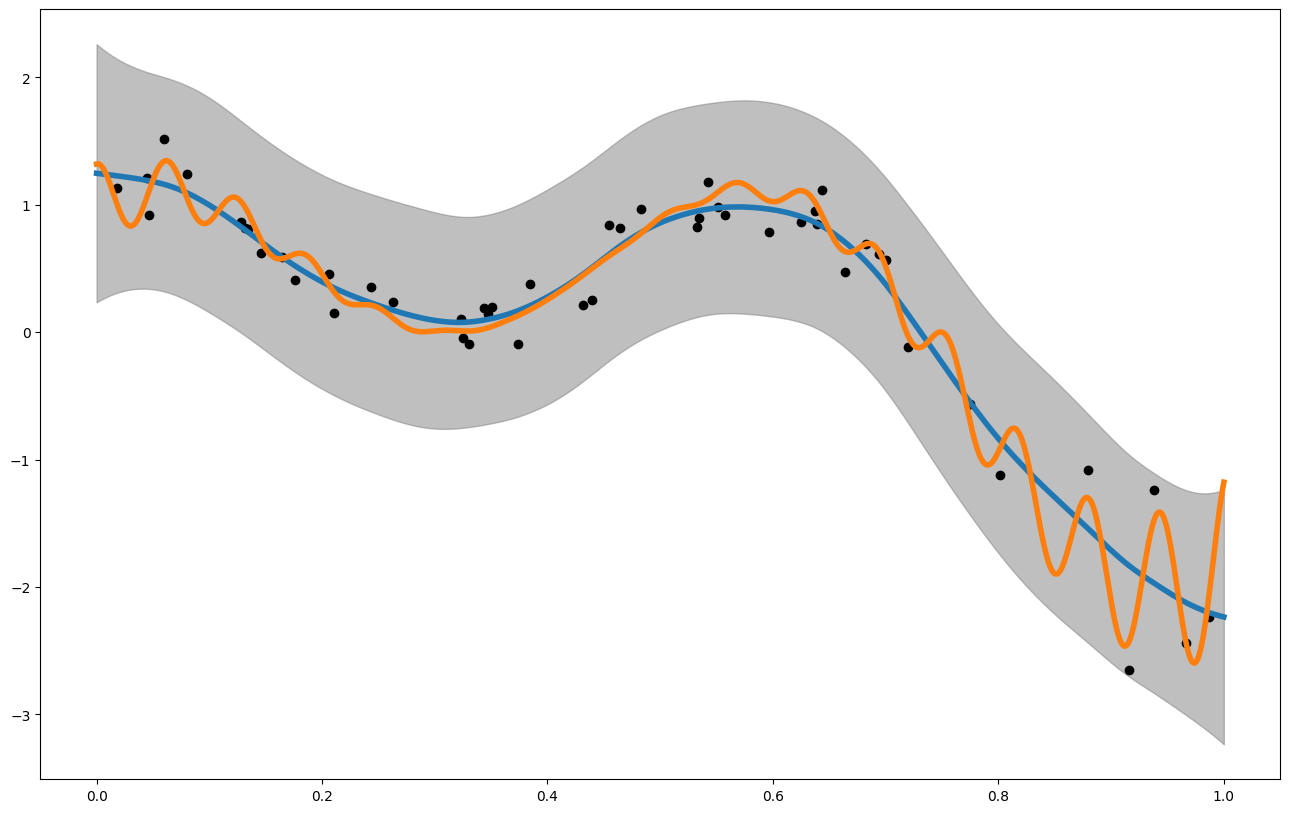

Posterior Mean Gradient


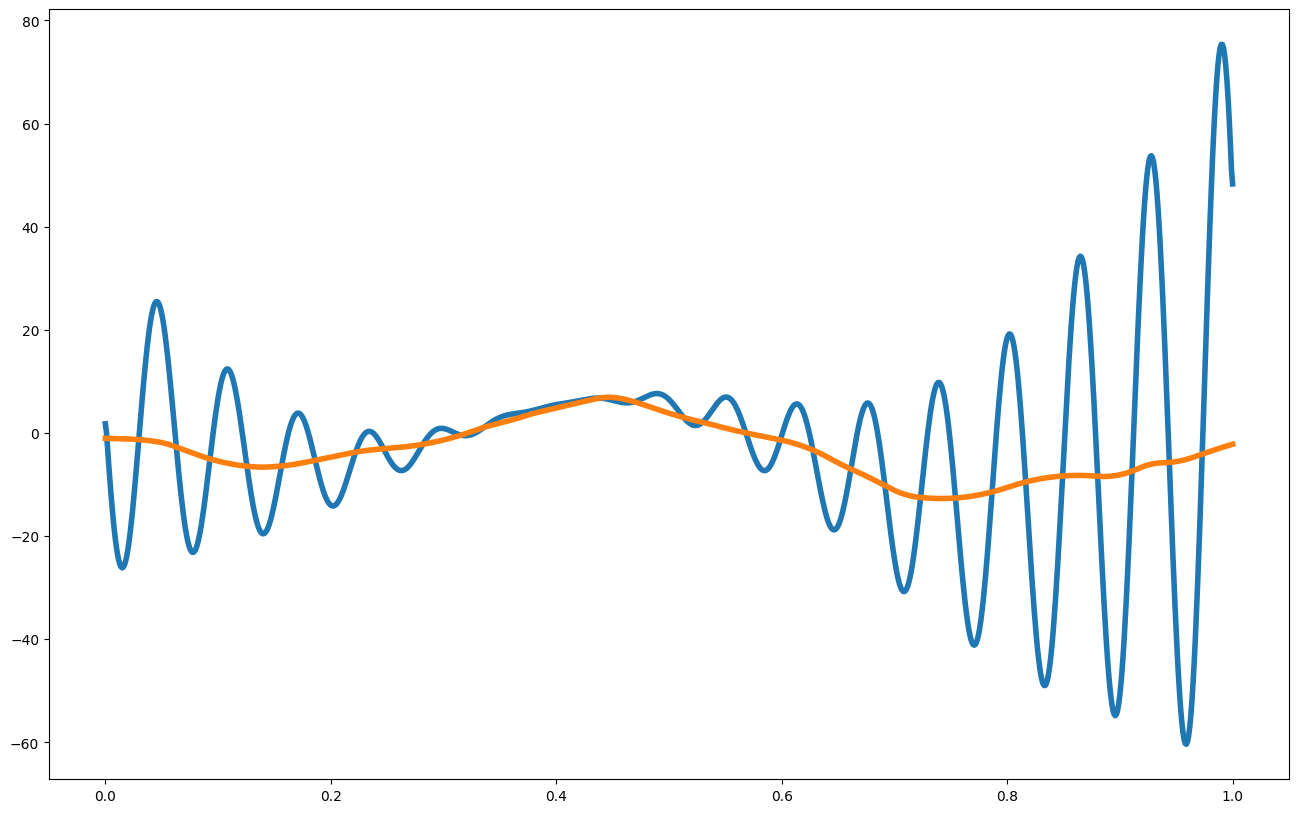

RMSE:              0.20818670963757485
NRMSE:             0.052786958086384526
CRPS (mean, std):  (np.float64(0.10706195343004121), np.float64(0.12665386722492436))
R2:                0.9592904813913518
NLPD:              -0.0921438331901473
MSLL:              -1.5906143319251513
MAPE:              1.737893555062988
INTERVAL SCORE:    1.2195824634271362
MPIW:              1.1190999312236614
PICP:              0.973
Coverage Curve:


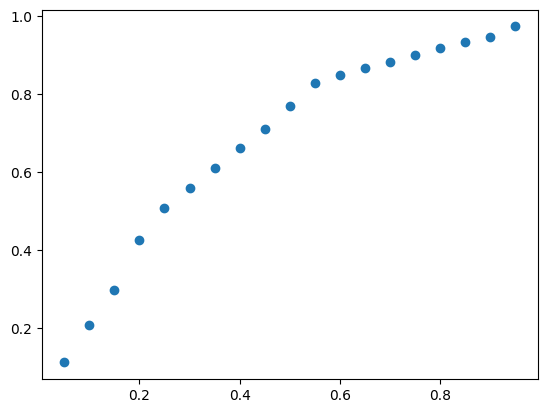

predicted vs. observed


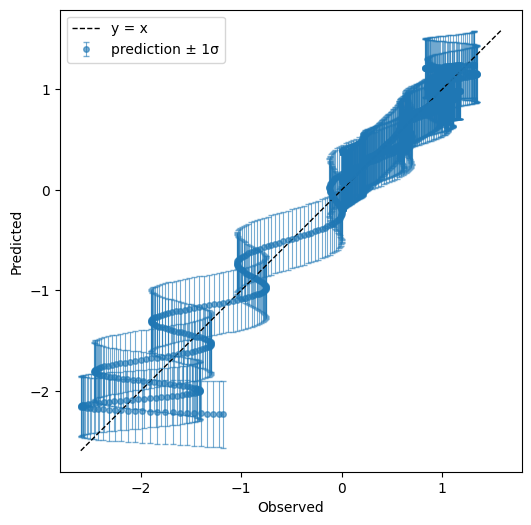

In [22]:
#let's make a prediction
x_pred = np.linspace(0,1,1000)
hps = my_gpo.train(hyperparameter_bounds=hps_bounds, info = False)

# different ways to call 
var1 =  my_gpo.posterior_covariance(x_pred.reshape(-1,1), variance_only=False, add_noise=False)["v(x)"]
var1 =  my_gpo.posterior_covariance(x_pred.reshape(-1,1), variance_only=False, add_noise=True)["v(x)"]

mean1 = my_gpo.posterior_mean(x_pred.reshape(-1,1))["m(x)"]
var1 =  my_gpo.posterior_covariance(x_pred.reshape(-1,1), variance_only=False, add_noise=True)["v(x)"]
mean_grad = my_gpo.posterior_mean_grad(x_pred.reshape(-1,1), direction=0)["dm/dx"]

print("Posterior Mean and Uncertainty")
plt.figure(figsize = (16,10))
plt.plot(x_pred,mean1, label = "posterior mean", linewidth = 4)
plt.plot(x_pred1D,f1(x_pred1D), label = "latent function", linewidth = 4)
plt.fill_between(x_pred, mean1 - 3. * np.sqrt(var1), mean1 + 3. * np.sqrt(var1), alpha = 0.5, color = "grey", label = "var")
plt.scatter(my_gpo.x_data,my_gpo.y_data, color = 'black')
plt.show()

print("Posterior Mean Gradient")
plt.figure(figsize = (16,10))
dx = 1./len(x_pred)
plt.plot(x_pred1D,np.gradient(f1(x_pred1D).flatten(), dx), label = "ground truth gradient", linewidth = 4)
plt.plot(x_pred1D,mean_grad, label = "posterior mean grad", linewidth = 4)
plt.show()



##looking at some validation metrics
print("RMSE:             ",my_gpo.rmse(x_pred1D,f1(x_pred1D).flatten()))
print("NRMSE:            ",my_gpo.nrmse(x_pred1D,f1(x_pred1D).flatten()))
print("CRPS (mean, std): ",my_gpo.crps(x_pred1D,f1(x_pred1D).flatten()))
print("R2:               ",my_gpo.r2(x_pred1D,f1(x_pred1D).flatten()))
print("NLPD:             ",my_gpo.nlpd(x_pred1D,f1(x_pred1D).flatten()))
print("MSLL:             ",my_gpo.msll(x_pred1D,f1(x_pred1D).flatten()))
print("MAPE:             ",my_gpo.mape(x_pred1D,f1(x_pred1D).flatten()))
print("INTERVAL SCORE:   ",my_gpo.interval_score(x_pred1D,f1(x_pred1D).flatten()))
print("MPIW:             ",my_gpo.mpiw(x_pred1D))
print("PICP:             ",my_gpo.picp(x_pred1D,f1(x_pred1D).flatten()))
print("Coverage Curve:")
cov_curve = my_gpo.coverage_curve(x_pred1D,f1(x_pred1D).flatten())
plt.scatter(cov_curve["target_coverage"], cov_curve["measured_coverage"])
plt.show()

print("predicted vs. observed")
my_gpo.plot_observed_vs_predicted(x_pred1D,f1(x_pred1D).flatten())

## Acquisition Functions
All built-in single-task acquisition functions, plus a user-defined one. Each is **maximized** by `ask()`:

- `variance`: the posterior standard deviation -- pure exploration;
- `relative information entropy`: how far the data moved prior to posterior at a *set* of points (one score per set);
- `relative information entropy set`: the same, point by point;
- `ucb` / `lcb`: mean ± 3 std -- optimistic maximization / minimization;
- `maximum` / `minimum`: the posterior mean itself -- pure exploitation;
- `gradient`: large mean gradients weighted by uncertainty -- finds edges and transitions;
- `expected improvement` / `probability of improvement`: improvement over the best observation;
- `target probability`: the probability that f(x) lies in `[args['a'], args['b']]`;
- `total correlation`: how redundant a *set* of points is with the data and itself (one score per set);
- `knowledge gradient`: the expected gain in the best posterior mean after measuring at x;
- `noisy expected improvement`: expected improvement over a noisy incumbent.

In [23]:
#available acquisition functions for the single-task case:
acquisition_functions = ["variance","relative information entropy","relative information entropy set",
                         "ucb","lcb","maximum","minimum","gradient","expected improvement",
                         "probability of improvement", "target probability", "total correlation",
                         "knowledge gradient", "noisy expected improvement"]

#a user-defined acquisition function: gets the points and the GPOptimizer, returns one score per point
def my_acquisition(x, gpo):
    #exploration, preferring the left side of the domain
    std = np.sqrt(gpo.posterior_covariance(x, variance_only=True)["v(x)"])
    return std * np.exp(-2. * x[:, 0])

One score for the whole set of points (set-valued): relative information entropy [-866.69311819]
One score for the whole set of points (set-valued): total correlation [-7935.41017469]


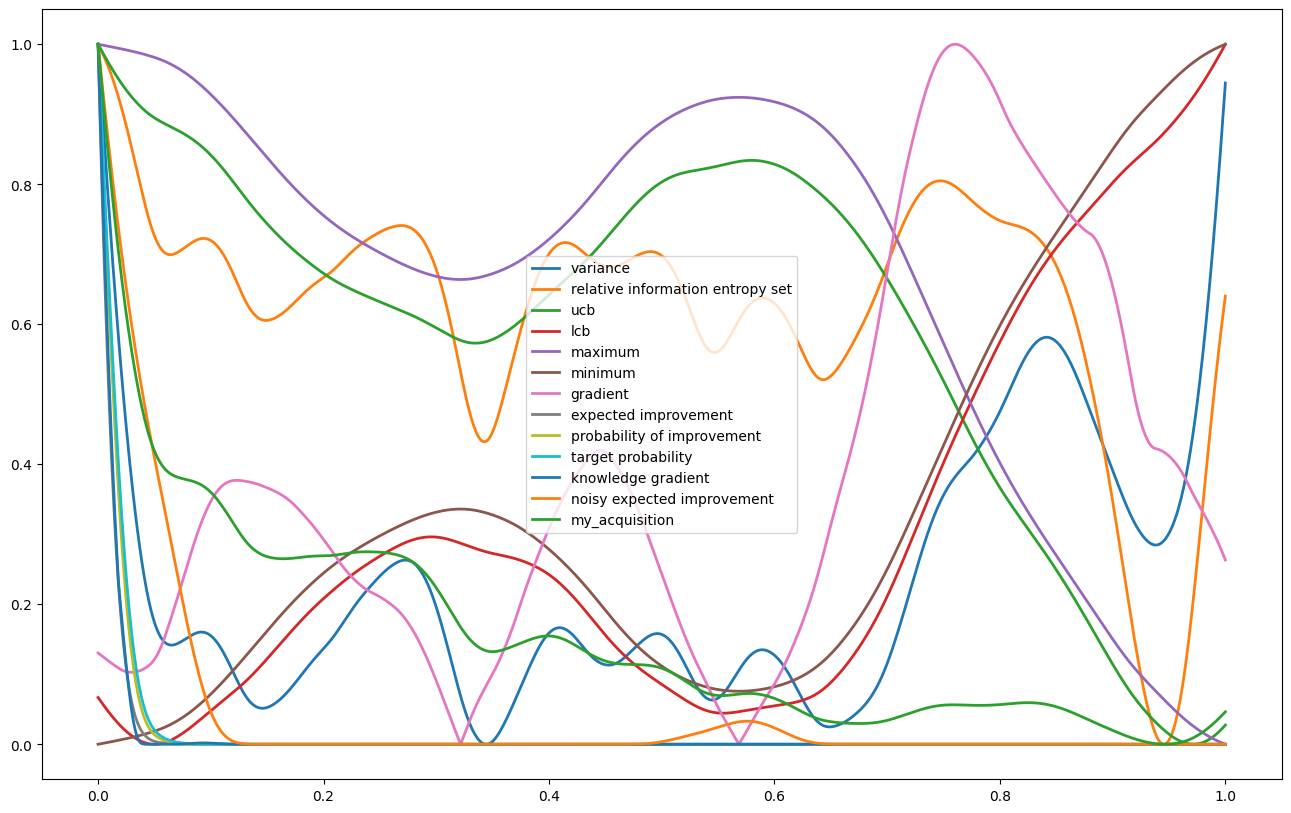

In [24]:
plt.figure(figsize=(16,10))
for acq_func in acquisition_functions + [my_acquisition]:
    name = acq_func if isinstance(acq_func, str) else acq_func.__name__
    res = my_gpo.evaluate_acquisition_function(x_pred, acquisition_function=acq_func)
    if len(res)==len(x_pred):
        res = res - np.min(res)
        res = res/np.max(res)
        plt.plot(x_pred,res, label = name, linewidth = 2)
    else: print("One score for the whole set of points (set-valued):", name, res)
plt.legend()
plt.show()

## ask()ing for Optimal Evaluations
Every acquisition function once, with the default optimizer (`global`); then every optimizer once, with
one acquisition function. All combinations work, but trying them all would take a while.

In [25]:
bounds = np.array([[0.0,1.0]])
for acq_func in acquisition_functions + [my_acquisition]:
    name = acq_func if isinstance(acq_func, str) else acq_func.__name__
    t0 = time.time()
    new_suggestion = my_gpo.ask(bounds, acquisition_function=acq_func, method="global", max_iter=5)
    print(f"{name:35s} x = {new_suggestion['x'].ravel()},  f_a(x) = {new_suggestion['f_a(x)']},  {time.time() - t0:.1f} s")

variance                            x = [0.99486529],  f_a(x) = [0.19616633],  0.0 s
relative information entropy        x = [0.00643785],  f_a(x) = [-20.35616502],  0.0 s
relative information entropy set    x = [0.7471997],  f_a(x) = [-51.73083717],  0.0 s
ucb                                 x = [0.00047397],  f_a(x) = [1.89537472],  0.0 s
lcb                                 x = [0.99740689],  f_a(x) = [2.83867223],  0.0 s
maximum                             x = [0.00464254],  f_a(x) = [1.24264632],  0.0 s
minimum                             x = [0.9970272],  f_a(x) = [2.22820025],  0.0 s
gradient                            x = [0.76067623],  f_a(x) = [1.74376433],  0.0 s
expected improvement                x = [0.00116092],  f_a(x) = [0.01021904],  0.0 s
probability of improvement          x = [0.00319772],  f_a(x) = [0.09217589],  0.0 s
target probability                  x = [0.01569356],  f_a(x) = [0.05735569],  0.0 s
total correlation                   x = [0.84088456],  f_a(x) =

/home/marcus/Coding/gpCAM/gpcam/gp_optimizer_base.py:596: UserWarning: I set vectorized=False for total corr. or rel. inf. entropy.
  warnings.warn("I set vectorized=False for total corr. or rel. inf. entropy.")


In [26]:
for method in ["global", "local", "hgdl"]:
    t0 = time.time()
    new_suggestion = my_gpo.ask(bounds, acquisition_function="ucb", method=method, max_iter=5, dask_client=client)
    print(f"{method:8s} x = {new_suggestion['x'].ravel()},  f_a(x) = {new_suggestion['f_a(x)']},  {time.time() - t0:.1f} s")

global   x = [0.0004789],  f_a(x) = [1.8953219],  0.0 s
local    x = [0.],  f_a(x) = [1.90046473],  0.0 s
hgdl     x = [0.],  f_a(x) = [1.90046473],  0.3 s


In [27]:
#here we can test other options of the ask() command
bounds = np.array([[0.0,1.0]])
new_suggestion = my_gpo.ask(bounds, acquisition_function="total correlation", method="global",
                            max_iter=10, n = 5, info = True)
my_gpo.ask(bounds, n = 5, acquisition_function="variance", vectorized=True, method = 'global')
my_gpo.ask(bounds, n = 1, acquisition_function="relative information entropy", vectorized=True, method = 'global')
my_gpo.ask(bounds, n = 2, acquisition_function="expected improvement", vectorized=True, method = 'global')
my_gpo.ask(bounds, n = 1, acquisition_function="variance", vectorized=True, method = 'global')
my_gpo.ask(bounds, n = 3, acquisition_function="variance", vectorized=True, method = 'hgdl', dask_client=client)
print(new_suggestion)

differential_evolution step 1: f(x)= 21.423675782622663
differential_evolution step 2: f(x)= 21.28106843571501
differential_evolution step 3: f(x)= 20.98246840677663
differential_evolution step 4: f(x)= 20.64557951883452
differential_evolution step 5: f(x)= 20.64557951883452
differential_evolution step 6: f(x)= 20.64557951883452
differential_evolution step 7: f(x)= 20.64557951883452
differential_evolution step 8: f(x)= 20.502398501344285
differential_evolution step 9: f(x)= 20.502398501344285
differential_evolution step 10: f(x)= 20.502398501344285


/home/marcus/Coding/gpCAM/gpcam/gp_optimizer_base.py:592: UserWarning: You specified n>1 and method != 'hgdl' in ask(). The acquisition function has therefore been changed to 'total correlation'.
  warnings.warn("You specified n>1 and method != 'hgdl' in ask(). The acquisition function "


{'x': array([[0.27235123],
       [0.51652426],
       [0.7486499 ],
       [0.78754676],
       [0.84231064]]), 'f_a(x)': array([-20.5023985]), 'opt_obj': None}


In [28]:
#we can evaluate the acqisiiton function on batches of candidates in parallel:
candidates = np.random.uniform(low = bounds[:,0], high=bounds[:,1], size = (30,1))
candidate_list = [entry for entry in candidates]

In [29]:
#ask sequentially
print("suggestions=", my_gpo.ask(candidate_list, n = 30, acquisition_function="variance", vectorized=False)["x"][0])
#ask in parallel on DASK workers, but sequentially on each worker:
print("suggestions=", my_gpo.ask(candidate_list, n = 30, acquisition_function="variance", vectorized=False, batch_size = 10, dask_client=client)["x"][0])
#ask in parallel on DASK workers, and vectorized (if possible) on each worker:
print("suggestions=", my_gpo.ask(candidate_list, n = 30, acquisition_function="variance", vectorized=True, batch_size = 10, dask_client=client)["x"][0])
#ask vectorized (if possible):
print("suggestions=", my_gpo.ask(candidate_list, n = 30, acquisition_function="variance", vectorized=True)["x"][0])
print("They should be the same!")

suggestions= [0.98928984]
suggestions= [0.98928984]
suggestions= [0.98928984]
suggestions= [0.98928984]
They should be the same!


/home/marcus/Coding/gpCAM/gpcam/surrogate_model.py:109: UserWarning: ask() is returning the 30 individually best candidates under `variance`, which scores one point at a time. They are not mutually optimal and are often near-duplicates, since nothing stops the top scorers from sitting on top of each other. For a batch chosen to be jointly informative use ['relative information entropy', 'total correlation'], which score a whole set.
  warnings.warn(


In [30]:
#With a set-valued acquisition ("total correlation" or "relative information entropy") ask() picks the n candidates that are most informative TOGETHER rather than the n best individually, and f_a(x) scores the whole batch instead of each point:
print("jointly chosen batch=", my_gpo.ask(candidate_list, n = 5, acquisition_function="total correlation"))

jointly chosen batch= {'x': array([[0.82233849],
       [0.74102777],
       [0.10454175],
       [0.51233686],
       [0.40307699]]), 'f_a(x)': array([-19.86064648]), 'opt_obj': None}


In [31]:
bounds = np.array([[0.0,1.0]])

#You can even start an ask() search asynchronously and check back later what was found
new_suggestion = my_gpo.ask(bounds, acquisition_function=acquisition_functions[0], method="hgdlAsync", dask_client=client)
time.sleep(10)
#the 'x' returned by ask() is a placeholder here; the optimizer object holds what was found so far
print(new_suggestion["opt_obj"].get_latest()[0]["x"])
new_suggestion["opt_obj"].kill_client()

[0.84148067]


[{'x': array([0.84148067]),
  'f(x)': np.float64(-0.16470420801746774),
  'classifier': 'minimum',
  'Hessian eigvals': array([21.67405144]),
  'df/dx': array([-4.54997151e-07]),
  '|df/dx|': np.float64(4.549971510670048e-07),
  'radius': np.float64(0.0461381206302603)},
 {'x': array([0.40938011]),
  'f(x)': np.float64(-0.11222726657259068),
  'classifier': 'minimum',
  'Hessian eigvals': array([21.22264864]),
  'df/dx': array([-4.95617436e-07]),
  '|df/dx|': np.float64(4.956174359804777e-07),
  'radius': np.float64(0.04711947208076619)},
 {'x': array([0.49603549]),
  'f(x)': np.float64(-0.11117248884090968),
  'classifier': 'minimum',
  'Hessian eigvals': array([18.50995746]),
  'df/dx': array([4.28421187e-07]),
  '|df/dx|': np.float64(4.284211874150401e-07),
  'radius': np.float64(0.05402497560542302)},
 {'x': array([0.58911861]),
  'f(x)': np.float64(-0.10824920107717348),
  'classifier': 'minimum',
  'Hessian eigvals': array([18.33599939]),
  'df/dx': array([-2.68715605e-07]),
  '|